In [34]:
%pip install -q datasets

import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from nltk.stem import PorterStemmer

print("libraries imported successfully")


libraries imported successfully


In [35]:
dataset = load_dataset("stanfordnlp/imdb")

train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

print("\nFirst five reviews:")
display(train_df.head())


Training dataset shape: (25000, 2)
Testing dataset shape: (25000, 2)

First five reviews:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


In [36]:
label_names = {
    0: "Negative",
    1: "Positive"
}

print("Class distribution in training data:")
print(train_df["label"].map(label_names).value_counts())

print("\nClass distribution in testing data:")
print(test_df["label"].map(label_names).value_counts())

print("\nMissing values in training data:")
print(train_df[["text", "label"]].isna().sum())

print("\nMissing values in testing data:")
print(test_df[["text", "label"]].isna().sum())


Class distribution in training data:
label
Negative    12500
Positive    12500
Name: count, dtype: int64

Class distribution in testing data:
label
Negative    12500
Positive    12500
Name: count, dtype: int64

Missing values in training data:
text     0
label    0
dtype: int64

Missing values in testing data:
text     0
label    0
dtype: int64


In [37]:
stemmer = PorterStemmer()

stop_words = set(ENGLISH_STOP_WORDS)
negation_words = {"no", "not", "nor", "never"}
stop_words = stop_words - negation_words

def preprocess_text(text):
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = text.lower()
    tokens = re.findall(r"\b[a-z]+\b", text)

    processed_tokens = [
        stemmer.stem(token)
        for token in tokens
        if token not in stop_words
    ]

    return " ".join(processed_tokens)

example = train_df.iloc[0]["text"]

print("Original review:")
print(example[:500])

print("\nProcessed review:")
print(preprocess_text(example)[:500])


Original review:
I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attent

Processed review:
rent curiou yellow video store controversi surround releas heard seiz u s custom tri enter countri fan film consid controversi realli plot center young swedish drama student name lena want learn life particular want focu attent make sort documentari averag swede thought certain polit issu vietnam war race issu unit state ask politician ordinari denizen stockholm opinion polit sex drama teacher classmat marri men kill curiou yellow year ago consid pornograph r

In [38]:
train_df["processed_text"] = train_df["text"].map(preprocess_text)
test_df["processed_text"] = test_df["text"].map(preprocess_text)

print("Processed review examples:")
display(
    train_df[["text", "processed_text", "label"]].head(3)
)

print(
    "\nNumber of empty processed reviews:",
    (train_df["processed_text"].str.strip() == "").sum()
)


Processed review examples:


,text,processed_text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,rent curiou yellow video store controversi sur...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",curiou yellow risibl pretenti steam pile doesn...,0
2,If only to avoid making this type of film in t...,avoid make type film futur film interest exper...,0



Number of empty processed reviews: 0


In [39]:
tfidf_example = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

example_texts = train_df["processed_text"].iloc[:1000]

example_matrix = tfidf_example.fit_transform(example_texts)

print("Number of documents:", example_matrix.shape[0])
print("Number of features:", example_matrix.shape[1])
print("Matrix shape:", example_matrix.shape)


Number of documents: 1000
Number of features: 10000
Matrix shape: (1000, 10000)


In [40]:
training_sizes = [1000, 5000, 10000, 25000]

results = []
trained_models = {}

for size in training_sizes:
    print(f"\nTraining set size: {size}")

    subset = (
        train_df.groupby("label", group_keys=False)
        .sample(n=size // 2, random_state=42)
        .sample(frac=1, random_state=42)
        .reset_index(drop=True)
    )

    vectorizer = TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2
    )

    X_train = vectorizer.fit_transform(subset["processed_text"])
    X_test = vectorizer.transform(test_df["processed_text"])

    y_train = subset["label"]
    y_test = test_df["label"]

    models = {
        "Naive Bayes": MultinomialNB(),
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    }

    for model_name, model in models.items():
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        metrics = {
            "Training Set Size": size,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predictions, zero_division=0
            )
        }

        results.append(metrics)

        if size == 25000:
            trained_models[model_name] = {
                "model": model,
                "vectorizer": vectorizer
            }

        print(
            model_name,
            "| Accuracy:",
            round(metrics["Accuracy"], 4),
            "| F1-score:",
            round(metrics["F1-score"], 4)
        )

results_df = pd.DataFrame(results)

print("\nModel comparison:")
display(
    results_df.sort_values(
        ["Model", "Training Set Size"]
    ).reset_index(drop=True)
)



Training set size: 1000
Naive Bayes | Accuracy: 0.8107 | F1-score: 0.8023
Logistic Regression | Accuracy: 0.8155 | F1-score: 0.818

Training set size: 5000
Naive Bayes | Accuracy: 0.831 | F1-score: 0.8219
Logistic Regression | Accuracy: 0.8508 | F1-score: 0.8519

Training set size: 10000
Naive Bayes | Accuracy: 0.8418 | F1-score: 0.8372
Logistic Regression | Accuracy: 0.8663 | F1-score: 0.8672

Training set size: 25000
Naive Bayes | Accuracy: 0.8501 | F1-score: 0.8466
Logistic Regression | Accuracy: 0.8806 | F1-score: 0.8809

Model comparison:


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score
0,1000,Logistic Regression,0.81552,0.807261,0.82896,0.817967
1,5000,Logistic Regression,0.85076,0.845318,0.85864,0.851927
2,10000,Logistic Regression,0.86628,0.861166,0.87336,0.867220
3,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878
4,1000,Naive Bayes,0.81068,0.839615,0.76808,0.802256
5,5000,Naive Bayes,0.83096,0.868257,0.78032,0.821943
6,10000,Naive Bayes,0.84184,0.862364,0.81352,0.837230
7,25000,Naive Bayes,0.85008,0.866868,0.82720,0.846570


In [41]:
import time
import pandas as pd
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

training_sizes = [1000, 5000, 10000, 25000]

results = []
trained_models = {}

for size in training_sizes:
    print(f"\nTraining set size: {size}")

    subset = (
        train_df.groupby("label", group_keys=False)
        .sample(n=size // 2, random_state=42)
        .sample(frac=1, random_state=42)
        .reset_index(drop=True)
    )

    vectorizer = TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2
    )

    X_train = vectorizer.fit_transform(subset["processed_text"])
    X_test = vectorizer.transform(test_df["processed_text"])

    y_train = subset["label"]
    y_test = test_df["label"]

    models = {
        "Naive Bayes": MultinomialNB(),
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    }

    for model_name, model in models.items():
        start_time = time.time()

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        elapsed_time = time.time() - start_time

        metrics = {
            "Training Set Size": size,
            "Model": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "Time (seconds)": round(elapsed_time, 2)
        }

        results.append(metrics)

        if size == 25000:
            trained_models[model_name] = {
                "model": model,
                "vectorizer": vectorizer
            }

        print(
            model_name,
            "| Accuracy:", round(metrics["Accuracy"], 4),
            "| F1-score:", round(metrics["F1-score"], 4),
            "| Time:", round(elapsed_time, 2), "seconds"
        )

results_df = pd.DataFrame(results)

print("\nModel comparison:")
display(
    results_df.sort_values(
        ["Model", "Training Set Size"]
    ).reset_index(drop=True)
)



Training set size: 1000
Naive Bayes | Accuracy: 0.8107 | F1-score: 0.8023 | Time: 0.02 seconds
Logistic Regression | Accuracy: 0.8155 | F1-score: 0.818 | Time: 0.73 seconds

Training set size: 5000
Naive Bayes | Accuracy: 0.831 | F1-score: 0.8219 | Time: 0.03 seconds
Logistic Regression | Accuracy: 0.8508 | F1-score: 0.8519 | Time: 0.56 seconds

Training set size: 10000
Naive Bayes | Accuracy: 0.8418 | F1-score: 0.8372 | Time: 0.03 seconds
Logistic Regression | Accuracy: 0.8663 | F1-score: 0.8672 | Time: 0.72 seconds

Training set size: 25000
Naive Bayes | Accuracy: 0.8501 | F1-score: 0.8466 | Time: 0.04 seconds
Logistic Regression | Accuracy: 0.8806 | F1-score: 0.8809 | Time: 0.55 seconds

Model comparison:


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,1000,Logistic Regression,0.81552,0.807261,0.82896,0.817967,0.73
1,5000,Logistic Regression,0.85076,0.845318,0.85864,0.851927,0.56
2,10000,Logistic Regression,0.86628,0.861166,0.87336,0.867220,0.72
3,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878,0.55
4,1000,Naive Bayes,0.81068,0.839615,0.76808,0.802256,0.02
5,5000,Naive Bayes,0.83096,0.868257,0.78032,0.821943,0.03
6,10000,Naive Bayes,0.84184,0.862364,0.81352,0.837230,0.03
7,25000,Naive Bayes,0.85008,0.866868,0.82720,0.846570,0.04


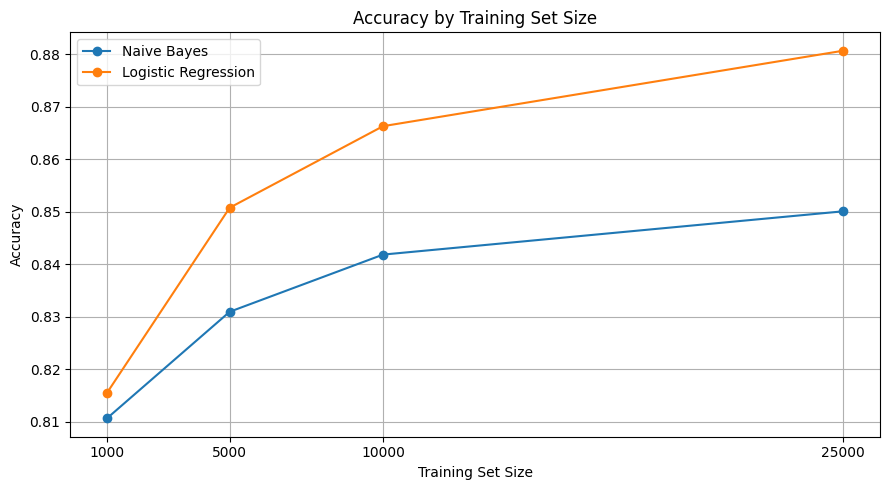

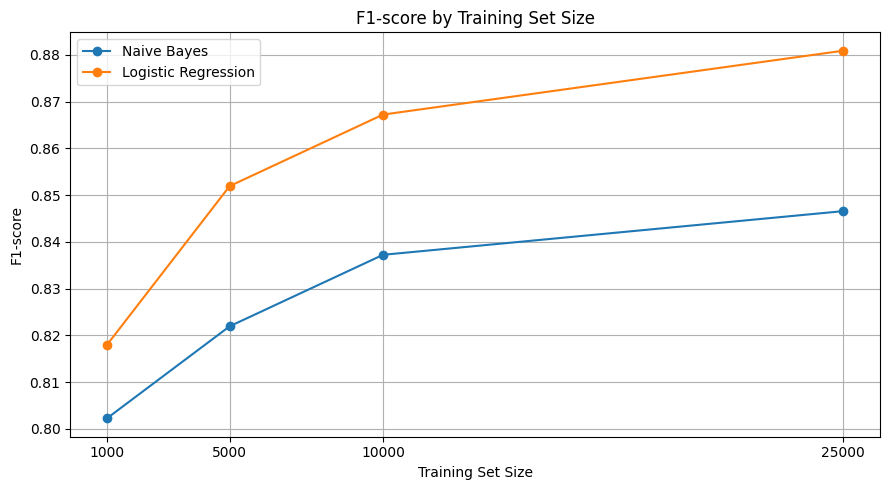

In [42]:
import matplotlib.pyplot as plt

metrics_to_plot = ["Accuracy", "F1-score"]

for metric in metrics_to_plot:
    plt.figure(figsize=(9, 5))

    for model_name in results_df["Model"].unique():
        model_results = results_df[
            results_df["Model"] == model_name
        ].sort_values("Training Set Size")

        plt.plot(
            model_results["Training Set Size"],
            model_results[metric],
            marker="o",
            label=model_name
        )

    plt.title(f"{metric} by Training Set Size")
    plt.xlabel("Training Set Size")
    plt.ylabel(metric)
    plt.xticks([1000, 5000, 10000, 25000])
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


In [43]:
comparison_df = results_df.sort_values(
    ["Training Set Size", "F1-score"],
    ascending=[True, False]
).reset_index(drop=True)

display(comparison_df)

print("\nBest F1-score for each model:")

best_results = (
    results_df.loc[
        results_df.groupby("Model")["F1-score"].idxmax()
    ]
    .sort_values("F1-score", ascending=False)
    .reset_index(drop=True)
)

display(best_results)


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,1000,Logistic Regression,0.81552,0.807261,0.82896,0.817967,0.73
1,1000,Naive Bayes,0.81068,0.839615,0.76808,0.802256,0.02
2,5000,Logistic Regression,0.85076,0.845318,0.85864,0.851927,0.56
3,5000,Naive Bayes,0.83096,0.868257,0.78032,0.821943,0.03
4,10000,Logistic Regression,0.86628,0.861166,0.87336,0.867220,0.72
5,10000,Naive Bayes,0.84184,0.862364,0.81352,0.837230,0.03
6,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878,0.55
7,25000,Naive Bayes,0.85008,0.866868,0.82720,0.846570,0.04



Best F1-score for each model:


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878,0.55
1,25000,Naive Bayes,0.85008,0.866868,0.82720,0.846570,0.04


Selected model: Logistic Regression
Confusion matrix:
[[10983  1517]
 [ 1467 11033]]


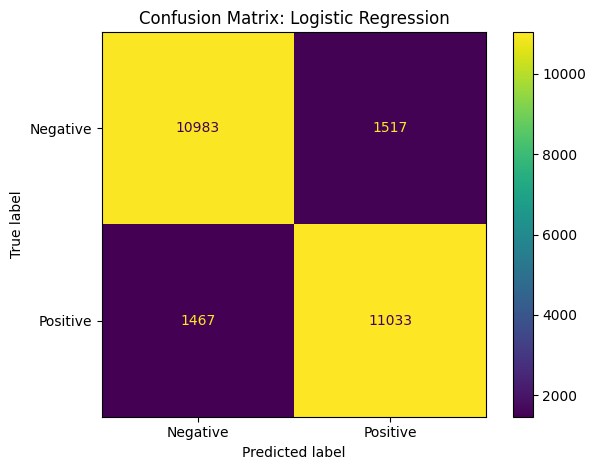


Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.88      0.88     12500
    Positive       0.88      0.88      0.88     12500

    accuracy                           0.88     25000
   macro avg       0.88      0.88      0.88     25000
weighted avg       0.88      0.88      0.88     25000



In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

best_model_name = "Logistic Regression"

best_model = trained_models[best_model_name]["model"]
best_vectorizer = trained_models[best_model_name]["vectorizer"]

X_test_best = best_vectorizer.transform(test_df["processed_text"])
y_test = test_df["label"]

best_predictions = best_model.predict(X_test_best)

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=[0, 1]
)

print("Selected model:", best_model_name)
print("Confusion matrix:")
print(cm)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

cm_display.plot(values_format="d")
plt.title("Confusion Matrix: Logistic Regression")
plt.tight_layout()
plt.show()

print("\nClassification report:")
print(
    classification_report(
        y_test,
        best_predictions,
        labels=[0, 1],
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)


In [45]:
error_df = test_df.copy()

error_df["Correct Label"] = y_test.to_numpy()
error_df["Predicted Label"] = best_predictions

misclassified_df = error_df[
    error_df["Correct Label"] != error_df["Predicted Label"]
].copy()

print("Selected model:", best_model_name)
print("Total test reviews:", len(error_df))
print("Misclassified reviews:", len(misclassified_df))
print(
    "Misclassification rate:",
    round(len(misclassified_df) / len(error_df), 4)
)

columns_to_show = [
    column
    for column in ["text", "processed_text"]
    if column in misclassified_df.columns
]

columns_to_show += ["Correct Label", "Predicted Label"]

display(misclassified_df[columns_to_show].head(10))


Selected model: Logistic Regression
Total test reviews: 25000
Misclassified reviews: 2984
Misclassification rate: 0.1194


,text,processed_text,Correct Label,Predicted Label
4,"First off let me say, If you haven't enjoyed a...",let say haven t enjoy van damm movi bloodsport...,0,1
6,Isaac Florentine has made some of the best wes...,isaac florentin best western martial art actio...,0,1
11,"Blind Date (Columbia Pictures, 1934), was a de...",blind date columbia pictur decent film issu fi...,0,1
20,Low budget horror movie. If you don't raise yo...,low budget horror movi don t rais expect high ...,0,1
32,I'm the type of guy who loves hood movies from...,m type guy love hood movi new jack citi babi b...,0,1
36,"Beware, My Lovely (1952) Dir: Harry Horner <br...",bewar love dir harri horner product filmmak rk...,0,1
41,Widow hires a psychopath as a handyman. Sloppy...,widow hire psychopath handyman sloppi film noi...,0,1
46,"Okay, so it was never going to change the worl...",okay never go chang world bomb box offic honki...,0,1
47,"A sprawling, overambitious, plotless comedy th...",sprawl overambiti plotless comedi no dramat ce...,0,1
61,This film features two of my favorite guilty p...,film featur favorit guilti pleasur sure effect...,0,1


In [46]:
custom_reviews = [
    "This movie was wonderful and deeply moving.",
    "The film was boring and a complete disappointment.",
    "The acting was excellent but the story was weak.",
    "I would definitely recommend this movie to everyone."
]

if "preprocess_text" in globals():
    text_preprocessor = preprocess_text
elif "clean_text" in globals():
    text_preprocessor = clean_text
else:
    raise NameError(
        "Find the text preprocessing function from the earlier steps "
        "and assign it to text_preprocessor."
    )

logistic_model = trained_models["Logistic Regression"]["model"]
logistic_vectorizer = trained_models["Logistic Regression"]["vectorizer"]

processed_reviews = [
    text_preprocessor(review)
    for review in custom_reviews
]

review_vectors = logistic_vectorizer.transform(processed_reviews)
predictions = logistic_model.predict(review_vectors)

for review, prediction in zip(custom_reviews, predictions):
    sentiment = "Positive" if prediction == 1 else "Negative"

    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print()


Review: This movie was wonderful and deeply moving.
Predicted sentiment: Positive

Review: The film was boring and a complete disappointment.
Predicted sentiment: Negative

Review: The acting was excellent but the story was weak.
Predicted sentiment: Positive

Review: I would definitely recommend this movie to everyone.
Predicted sentiment: Positive



In [47]:
comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

print("Model comparison across all training set sizes:")

display(
    results_df.sort_values(
        ["Training Set Size", "Model"]
    ).reset_index(drop=True)
)

print("\nF1-score comparison:")

f1_comparison = results_df.pivot(
    index="Training Set Size",
    columns="Model",
    values="F1-score"
)

display(f1_comparison)

print("\nLogistic Regression results:")

logistic_results = (
    results_df[
        results_df["Model"] == "Logistic Regression"
    ]
    .sort_values("Training Set Size")
    .reset_index(drop=True)
)

display(logistic_results)

print("\nLogistic Regression with 25000 training reviews:")

logistic_25000 = logistic_results[
    logistic_results["Training Set Size"] == 25000
].iloc[0]

for metric in comparison_metrics:
    print(f"{metric}: {logistic_25000[metric]:.4f}")


Model comparison across all training set sizes:


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,1000,Logistic Regression,0.81552,0.807261,0.82896,0.817967,0.73
1,1000,Naive Bayes,0.81068,0.839615,0.76808,0.802256,0.02
2,5000,Logistic Regression,0.85076,0.845318,0.85864,0.851927,0.56
3,5000,Naive Bayes,0.83096,0.868257,0.78032,0.821943,0.03
4,10000,Logistic Regression,0.86628,0.861166,0.87336,0.867220,0.72
5,10000,Naive Bayes,0.84184,0.862364,0.81352,0.837230,0.03
6,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878,0.55
7,25000,Naive Bayes,0.85008,0.866868,0.82720,0.846570,0.04



F1-score comparison:


Model,Logistic Regression,Naive Bayes
Training Set Size,,
1000,0.817967,0.802256
5000,0.851927,0.821943
10000,0.867220,0.837230
25000,0.880878,0.846570



Logistic Regression results:


,Training Set Size,Model,Accuracy,Precision,Recall,F1-score,Time (seconds)
0,1000,Logistic Regression,0.81552,0.807261,0.82896,0.817967,0.73
1,5000,Logistic Regression,0.85076,0.845318,0.85864,0.851927,0.56
2,10000,Logistic Regression,0.86628,0.861166,0.87336,0.867220,0.72
3,25000,Logistic Regression,0.88064,0.879124,0.88264,0.880878,0.55



Logistic Regression with 25000 training reviews:
Accuracy: 0.8806
Precision: 0.8791
Recall: 0.8826
F1-score: 0.8809
